# k-means 클러스터링의 최적의 k값을 찾는 방법

1. 비즈니스 도메인 지식
    - 정성적인 선정 방법
  
    - 데이터적인 근거는 다소 부족하지만, 클러스터링 자체가 해석을 통한 비즈니스 인사이트 도출이 주 목적이기 때문에 많은 프로젝트에서 이 방법을 사용
  
2. 엘보우 기법(Elbow method)
    - 군집 내 중심점과 관측치 간 거리 합(Inertia value)이 급감하는 구간의 k개수를 선정
  
    - 군집의 수가 k였을 때보다 k + 1 개일 때 거리합이 급감했다는 것은 유사한 속성의 관측치들끼리 잘 묶였다는 것을 의미
  
    - 따라서 k가 더 증가해도 거리합이 별로 줄어들지 않을 때는 k를 더 증가시킬 필요가 없다는 의미
        - 이 때의 그래프 모양이 팔꿈치(Elbow) 형태를 하고 있기 때문에 엘보우 기법이라고 불림
     
3. 실루엣 계수(Silhouette coefficient) 활용
    - 실루엣 계수 : 군집 안의 관측치들이 다른 군집과 비교해서 얼마나 비슷한지를 나타내는 수치
  
    - 동일한 군집 안에 있는 관측치들 간의 평균 거리와 가장 가까운 다른 군집과의 평균 거리를 구해 실루엣 계수를 계산
  
    - $$ S(i) = \frac{b(i) - a(i)}{\max({a(i), b(i)})} $$
        - $ a(i) $ : i 와 동일한 군집에 속한 관측치들 간의 평균 거리
        - $ b(i) $ : i 와 다른 군집 중 가장 가까운 군집까지의 평균 거리
     
    - 동일한 군집 내 관측치들 간 평균 거리가 집단 간 평균 거리보다 짧을수록 실루엣 계수는 높아짐
        - 범위는 -1부터 1 사이의 값을 가지며 실루엣 계수가 1에 가까울수록 군집이 적합하게 나누어졌음을 의미

# DBSCAN

- 아무리 k값을 잘 지정한다고 해도 데이터의 형태가 k-means 클러스터링 알고리즘에 적합하지 않으면 효과적인 군집화를 할 수가 없음

- 밀도 기반의 원리를 이용한 클러스터링 기법이 DBSCAN(Density-based spatial clustering of applications with noise)

- DBSCAN은 별도의 k값 지정이 필요 없고 관측치들의 밀도를 통해 자동으로 적절한 군집의 수를 찾음
    - 밀도를 측정하려면 두 가지 기준이 필요
        - 기준 관측치로부터 "이웃"한 관측치인지 구별할 수 있는 거리 기준(epsilon)이 필요
            - 거리 기준값이 크면 데이터 공간상 멀리 있는 관측치도 이웃한 관측치로 인식
     
        - 거리 기준 내에 포함된 이웃 관측치 수(minPts)에 대한 기준이 필요
            - 특정 거리 안에 몇 개 이상의 관측치가 있어야 하나의 군집으로 판단할 것인가를 결정
         
- 기준 밀도를 가진 관측치들을 기준으로 군집화를 하기 때문에 U자형과 같이 오복한 데이터나 H와 같은 모양의 데이터 분포도 효과적으로 군집화할 수 있고, 군집이 명확하지 않은 이상치를 잘 분류해낼 수 있음

- 하지만 k-means 에 비해 필요한 연산량이 많고, 특히 독립변수가 늘어날수록 필요한 연산량이 급증하기 때문에 변수를 적절히 설정해줘야 함

- 그리고 데이터 특성을 모를 경우에는 적절한 파라미터 값을 설정하는 것이 어려움

# 군집화 모델 분석

- 군집화 모델은 분류된 각 군집의 특성을 파악하여 군집에 이름을 붙여서 그 특징을 정의하는 작업이 무엇보다 중요
    - 클러스터링에 사용한 독립변수들이 다른 군집들에 비해서 어떠한 특성을 가지고 있는지를 확인하여 각 군집을 명확하게 정의해야 함
 
    - 그 다음 각 군집의 특성에 맞는 비즈니스 전략을 수립
 
- 각 군집에 어느 정도의 데이터가 할당 되었는지 확인하여, 특정 군집에 너무 많은 데이터가 쏠렸거나, 너무 적은 데이터가 할당되어 군집으로서 효율성이 떨어지는 군집은 없는지 확인

- 각 독립변수들이 다른 군집 혹은 전체 평균과 얼마나 다른지 확인하여 군집의 특성을 파악
    - 이를 통해 군집의 이름을 설정
 
    - 특성이 확실하여 쉽게 정의할 수 있는 군집도 있지만, 별다른 특성이 없는 군집도 있을 수 있음
        - 이 경우 무리해서 억지로 군집을 정의하기 보다는 비슷한 군집끼리 묶어서 "일반 고객" 등으로 별도 분류하는 것도 하나의 방법
     
- 군집 간의 수치적 차이를 보다 확실하게 파악하기 위해서는 t-test나 ANOVA 등을 통해 군집 간 평균값 차이가 우연한 차이인지, 통계적으로 유의미한 차이인지 검증하는 절차를 거치는 것이 좋음

In [23]:
from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [24]:
df = pd.read_csv("./data/Mall_Customers.csv")

In [25]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [26]:
df.shape

(200, 5)

In [27]:
df.dtypes

CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [29]:
df.describe(include = "all")

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


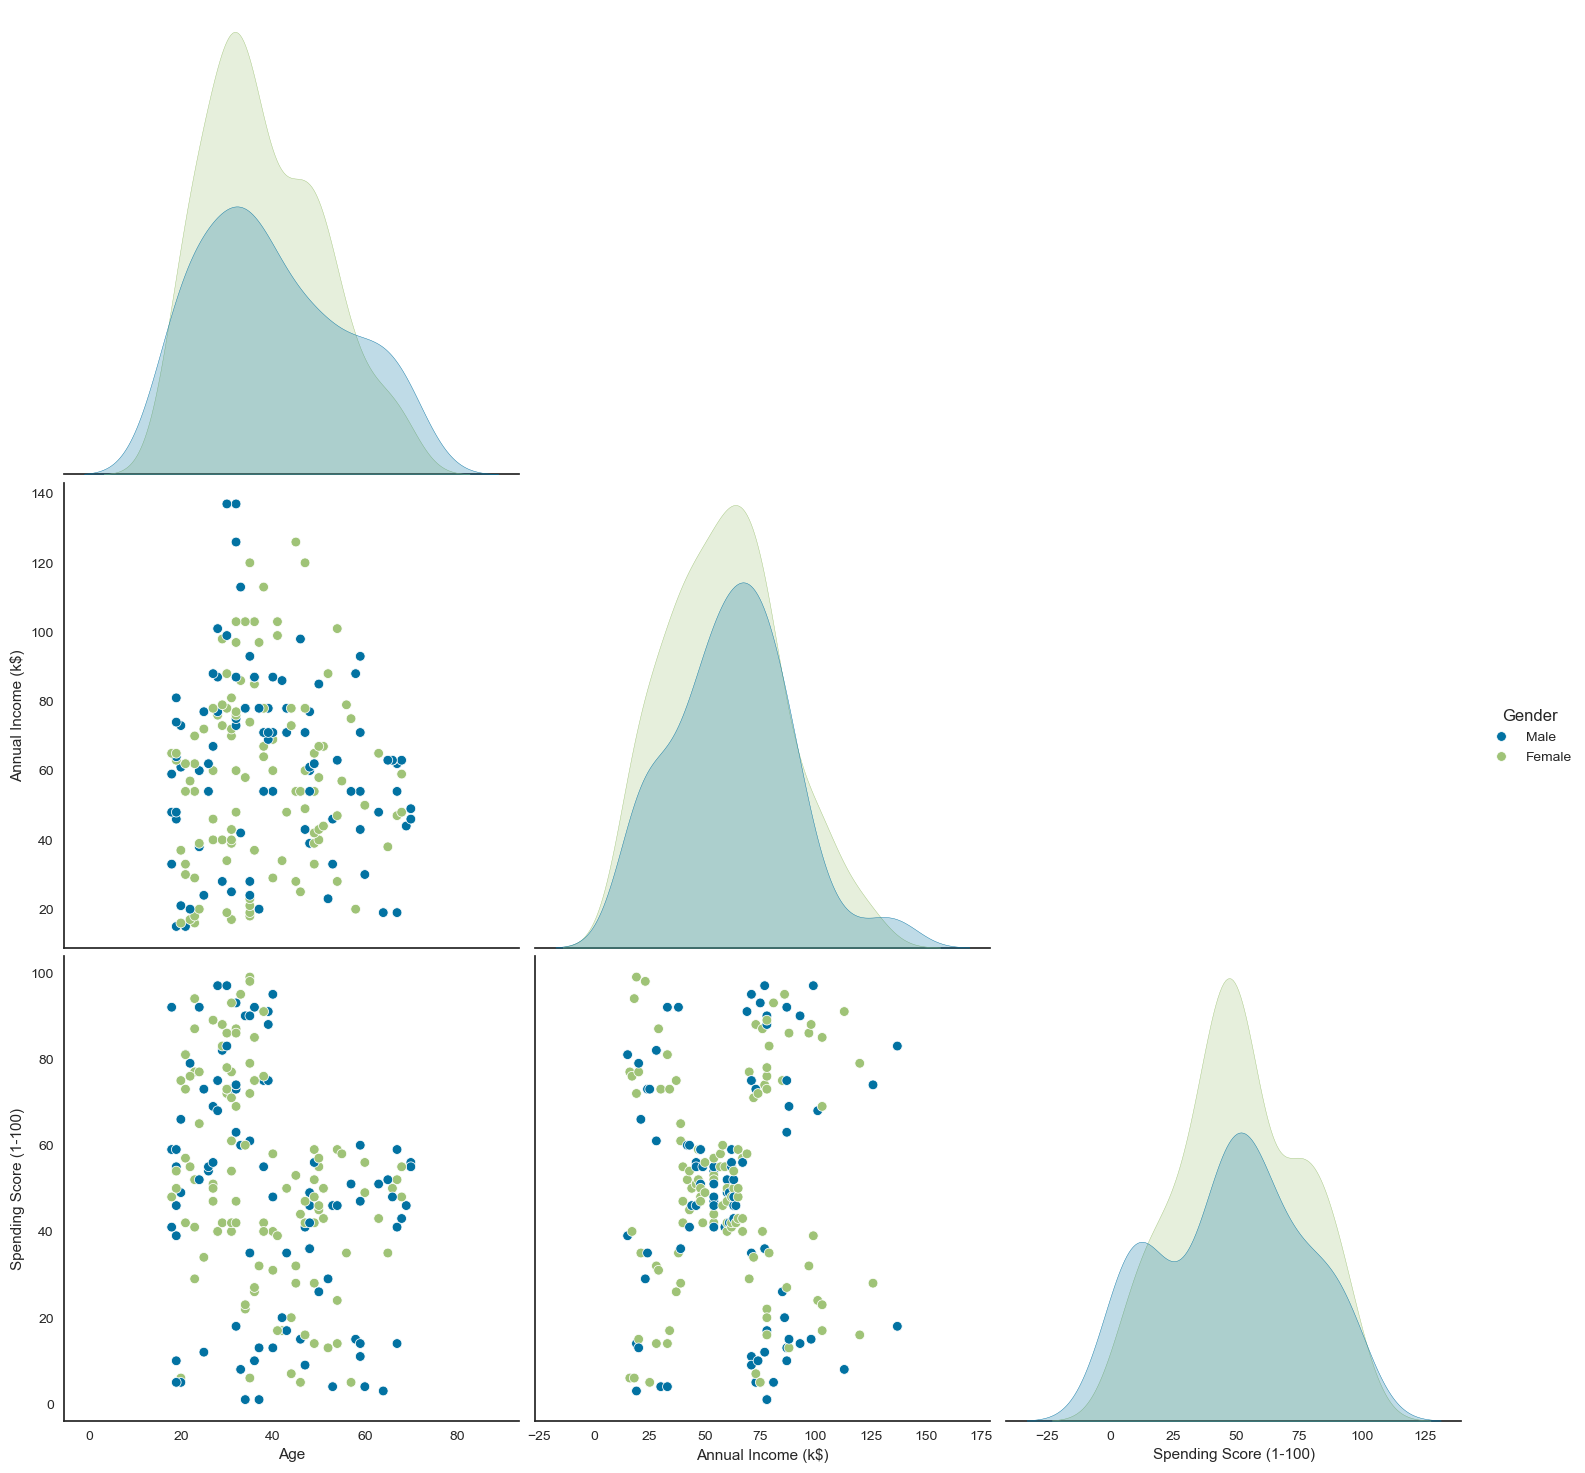

In [30]:
# pairplot
df1 = df.drop("CustomerID", axis = 1)

sns.set_style("ticks")
sns.pairplot(df1, diag_kind = "kde", hue = "Gender", corner = True, height = 5)
plt.show()

- 각 변수 간의 관계를 파악하기 위해 산점도 행렬을 시각화하여 분포를 확인

- spending score 변수와 annual income 변수와의 관계에서 약 5개 정도의 군집이 나눠질 수 있을 것으로 보이지만 연령과 성별 변수도 함께 사용하여 군집화할 예정이므로 이러한 분포는 참고로만 사용

In [31]:
# Gender 변수 전처리
df2 = pd.get_dummies(df1, columns = ["Gender"], drop_first = True)

In [32]:
df2.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender_Male
0,19,15,39,True
1,21,15,81,True
2,20,16,6,False
3,23,16,77,False
4,31,17,40,False


In [33]:
# 데이터 정규화 
mm = MinMaxScaler()
scaled_data = mm.fit_transform(df2)

In [34]:
scaled_data[:5]

array([[0.01923077, 0.        , 0.3877551 , 1.        ],
       [0.05769231, 0.        , 0.81632653, 1.        ],
       [0.03846154, 0.00819672, 0.05102041, 0.        ],
       [0.09615385, 0.00819672, 0.7755102 , 0.        ],
       [0.25      , 0.01639344, 0.39795918, 0.        ]])

- 거리 기반 군집화 알고리즘은 스케일링을 적용하는 것을 권장

In [35]:
# k-means 군집화 모델 생성
kmeans_model_1 = KMeans(n_clusters = 3, random_state = 26)
kmeans_model_1.fit(scaled_data)

KMeans(n_clusters=3, random_state=26)

In [36]:
print(kmeans_model_1.inertia_)

29.63233438025291


In [37]:
print(kmeans_model_1.cluster_centers_)

[[1.92307692e-01 3.87205987e-01 6.51286602e-01 1.00000000e+00]
 [3.86504121e-01 3.62704918e-01 5.15579446e-01 4.44089210e-16]
 [6.68040293e-01 3.87002342e-01 3.02478134e-01 1.00000000e+00]]


In [38]:
print(kmeans_model_1.n_iter_)

5


<Axes: >

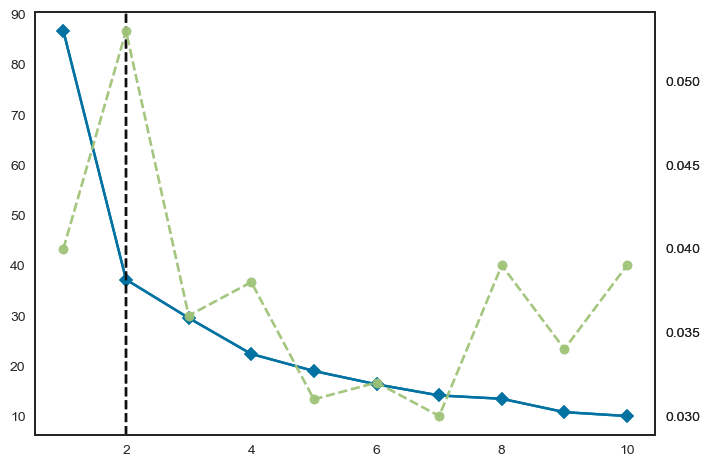

In [49]:
# 엘보우 차트 시각화
elbow_chart = KElbowVisualizer(kmeans_model_1, k = (1, 11),)
elbow_chart.fit(scaled_data)
elbow_chart.draw()

- 2 지점에서 경사가 급감하는 모습을 보이고 있음
    - 성별 변수 때문일 것으로 예상

In [43]:
# 실루엣 계수 시각화 1

# 각 K의 실루엣 계수 저장
silhouette_coef = []

# 실루엣 계수 그래프 생성
for k in range(2, 11):
    kmeans_silhouette = KMeans(n_clusters = k, random_state = 26)
    kmeans_silhouette.fit(scaled_data)
    score = silhouette_score(scaled_data, kmeans_silhouette.labels_)
    silhouette_coef.append(score)

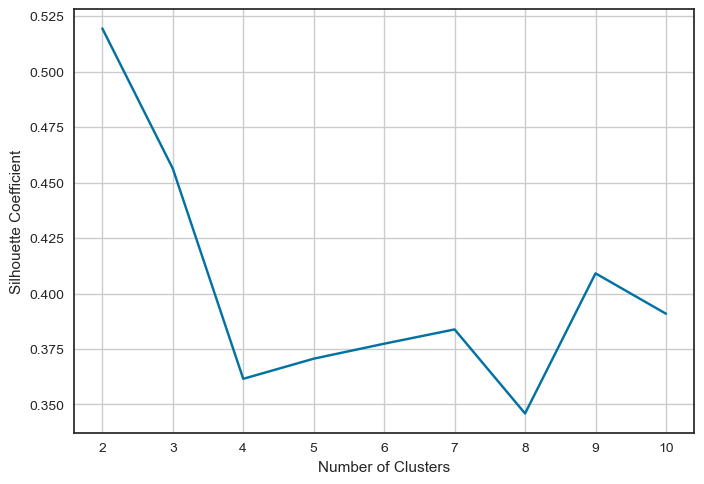

In [46]:
plt.plot(range(2, 11), silhouette_coef)
plt.xticks(range(2, 11))

plt.grid()
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Coefficient")
plt.show()

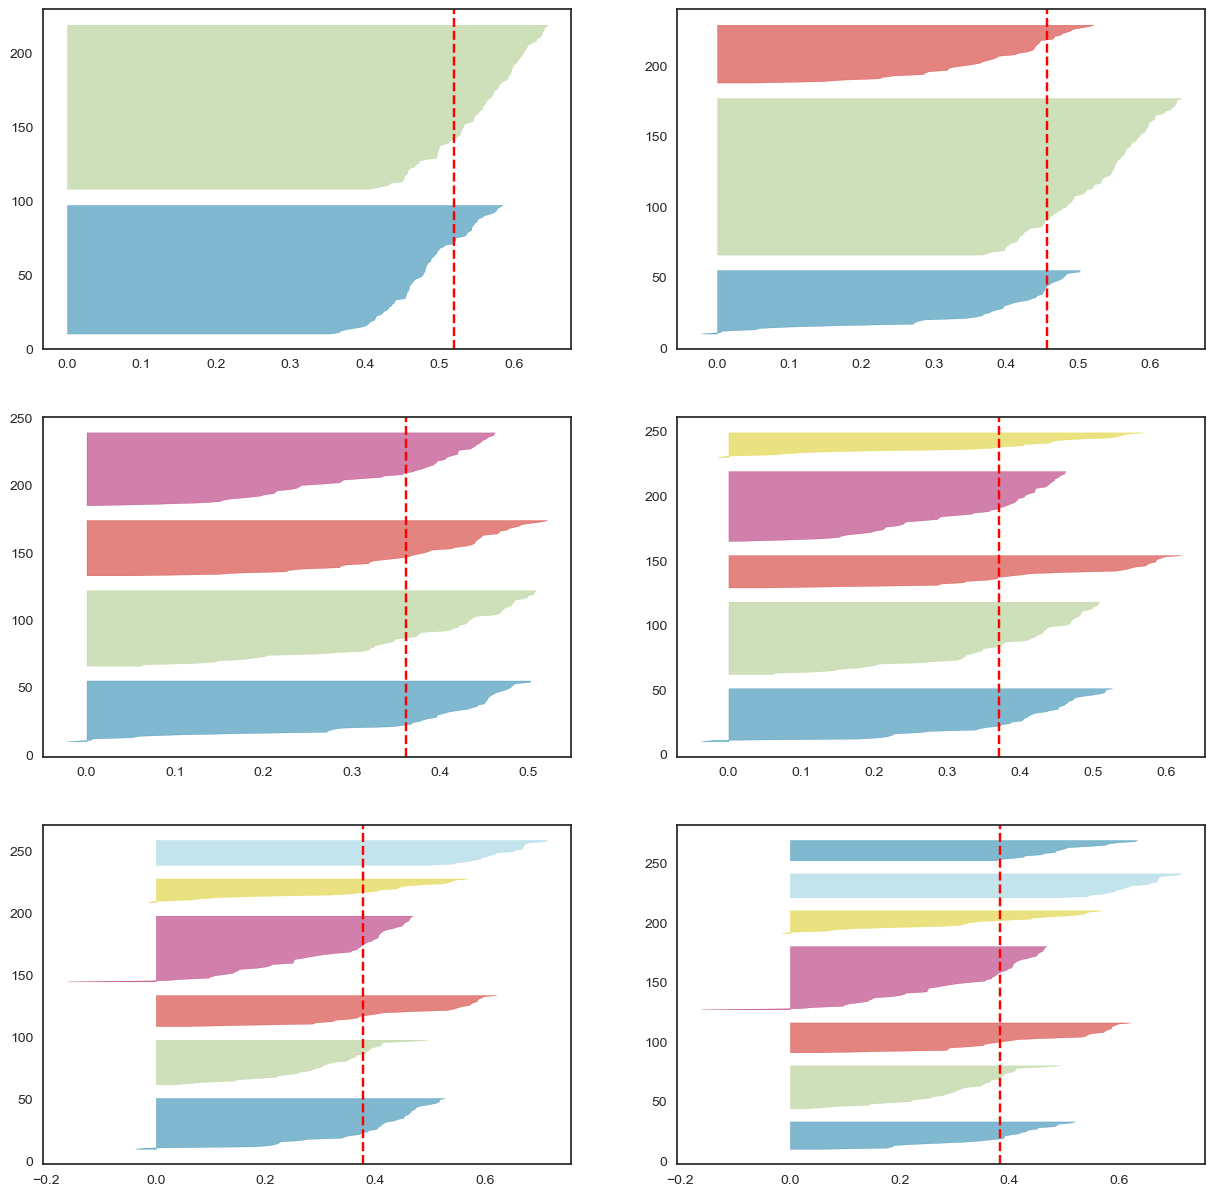

In [47]:
# 실루엣 계수 시각화 2
fig, ax = plt.subplots(3, 2, figsize = (15, 15))

for i in range(2, 8):
    # k-means 군집화 모델 생성
    kmeans_model_3 = KMeans(n_clusters = i, random_state = 26)
    q, mod = divmod(i, 2)

    # 실루엣 계수 시각화
    visualizer = SilhouetteVisualizer(kmeans_model_3, colors = "yellowbrick", ax = ax[q-1][mod])
    visualizer.fit(scaled_data)

- 4개의 군집이 관측치가 비교적 균등하게 나뉘며 실루엣 계수의 편차도 고른 편

- 6개의 군집부터는 일부 실루엣 계수의 음수가 크게 나타남

In [50]:
kmeans_model_4 = KMeans(n_clusters = 4, random_state = 26)

In [51]:
# 군집 번호 결합
df2["cluster1"] = kmeans_model_4.fit_predict(scaled_data)

In [52]:
df2.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender_Male,cluster1
0,19,15,39,True,0
1,21,15,81,True,0
2,20,16,6,False,3
3,23,16,77,False,1
4,31,17,40,False,1


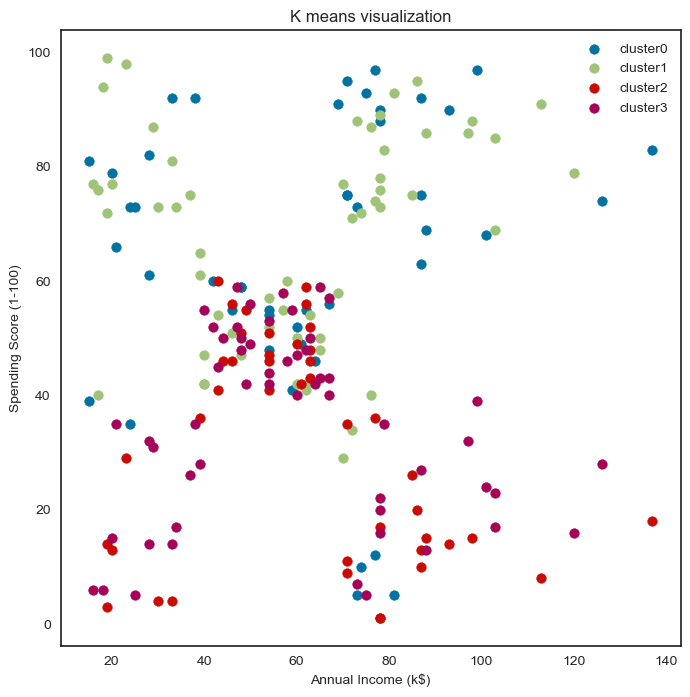

In [53]:
# 시각화
plt.figure(figsize = (8, 8))

for i in range(df2["cluster1"].max() + 1):
    plt.scatter(df2.loc[df2["cluster1"] == i, "Annual Income (k$)"],
                df2.loc[df2["cluster1"] == i, "Spending Score (1-100)"],
                label = "cluster" + str(i))

plt.legend()
plt.title("K means visualization", size = 12)
plt.xlabel("Annual Income (k$)", size = 10)
plt.ylabel("Spending Score (1-100)", size = 10)
plt.show()

- 4개의 군집으로 나눈 군집의 분포를 확인하기 위해 annual income 변수를 x축으로, spending score 변수를 y축으로 설정하여 시각화

In [54]:
# DBSCAN 모델 생성
dbscan_model = DBSCAN(eps = 0.7, min_samples = 5)

# 군집화 모델 학습 및 클러스터 예측 결과 반환
dbscan_model.fit(scaled_data)
df2["cluster2"] = dbscan_model.fit_predict(scaled_data)

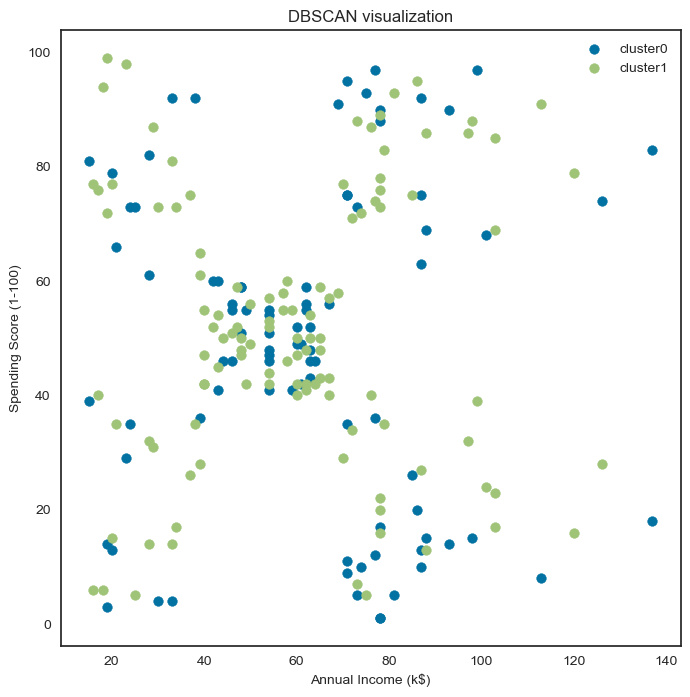

In [55]:
# 시각화
plt.figure(figsize = (8, 8))

for i in range(df2["cluster2"].max() + 1):
    plt.scatter(df2.loc[df2["cluster2"] == i, "Annual Income (k$)"],
                df2.loc[df2["cluster2"] == i, "Spending Score (1-100)"],
                label = "cluster" + str(i))

plt.legend()
plt.title("DBSCAN visualization", size = 12)
plt.xlabel("Annual Income (k$)", size = 10)
plt.ylabel("Spending Score (1-100)", size = 10)
plt.show()

- 밀도 기반의 DBSCAN 모델은 군집 수가 자동으로 설정
    - 관측치 간의 거리를 설정하는 eps 옵션과 한 군집에 속하는 최소 관측치 수를 설정하는 min_samples 옵션을 통해 군집 수를 간접적으로 조정할 수 있음

In [56]:
# k-means 군집 별 특성 확인
df_kmeans = df2.groupby("cluster1").mean()
df_kmeans["cnt"] = df2.groupby("cluster1")["Age"].count()

In [57]:
df_kmeans

,Age,Annual Income (k$),Spending Score (1-100),Gender_Male,cluster2,cnt
cluster1,,,,,,
0,28.000000,62.239130,64.826087,1.0,0.0,46
1,28.438596,59.666667,67.684211,0.0,1.0,57
2,52.738095,62.214286,30.642857,1.0,0.0,42
3,48.109091,58.818182,34.781818,0.0,1.0,55


In [60]:
df2.mean()

Age                       38.85
Annual Income (k$)        60.56
Spending Score (1-100)    50.20
Gender_Male                0.44
cluster1                   1.53
cluster2                   0.56
dtype: float64

In [61]:
# DBSCAN 군집 별 특성 확인
df_dbscan = df2.groupby("cluster2").mean()
df_dbscan["cnt"] = df2.groupby("cluster2")["Age"].count()
df_dbscan

,Age,Annual Income (k$),Spending Score (1-100),Gender_Male,cluster1,cnt
cluster2,,,,,,
0,39.806818,62.227273,48.511364,1.0,0.954545,88
1,38.098214,59.250000,51.526786,0.0,1.982143,112


- dbscan 모델의 경우 성별에 따라 두 개의 군집으로 나뉘어 졌음

- 성별이 범주형 변수이기 때문에 변별력이 강해서 다른 변수의 영향력을 압도한 것으로 보임
    - 비즈니스적으로 의미 있는 군집을 만들기 위해서는 성별 변수를 제거하거나 다른 변수를 추가해야함